In [1]:
.libPaths("~/R/x86_64-pc-linux-gnu-library/4.4/")

In [2]:
library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)

ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built with package ‘Matrix’ 1.7.4 but the current
version is 1.7.6; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Registered S3 method overwritten by 'SeuratDisk':
  method            from  
  as.sparse.H5Group Seurat

Loading required package: Rcpp


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts()

# Cohort baseline pre + post lab values plots

In [19]:
ls()

[1] "cd4_gut_3p" "df_filt"    "df4"        "ggtheme"    "md"        
[6] "md_gut_5p"  "md_to_join" "scibd"      "stat_test"

In [413]:
list.files("Files/Clinical_values")

[1] "albumin.csv"                          
 [2] "celltypist_combined_corrected.csv"    
 [3] "celltypist_combined.csv"              
 [4] "crp.csv"                              
 [5] "eosinophils_pct.csv"                  
 [6] "esr.csv"                              
 [7] "fecal_calprotectin.csv"               
 [8] "gut_export.h5ad"                      
 [9] "hematocrit.csv"                       
[10] "hemoglobin.csv"                       
[11] "lymphocytes_pct.csv"                  
[12] "neutrophils_pct.csv"                  
[13] "platelets.csv"                        
[14] "predict_5p_metadata_20260819.csv"     
[15] "scimilarity_combined_corrected.csv.gz"
[16] "scimilarity_combined.csv.gz"

In [414]:
test  <- read_csv('data/albumin.csv')

Rows: 295 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): participant_id, redcap_form
dbl (2): days_from_baseline, albumin

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [415]:
test

participant_id,days_from_baseline,albumin,redcap_form
<chr>,<dbl>,<dbl>,<chr>
001-002,0,5.4,clinical_lab_values
001-009,-39,4.5,clinical_lab_values
001-010,-36,4.0,clinical_lab_values
001-010,0,3.3,clinical_lab_values
001-010,58,4.5,clinical_lab_values
001-010,217,4.0,clinical_lab_values
001-010,231,4.1,clinical_lab_values
001-010,970,4.7,clinical_lab_values
001-010,1088,4.6,clinical_lab_values


In [426]:
labs_files  <- c('albumin.csv', 'crp.csv', 'eosinophils_pct.csv',
'esr.csv', 'fecal_calprotectin.csv', 'hematocrit.csv', 'hemoglobin.csv', 'lymphocytes_pct.csv',
'neutrophils_pct.csv', 'platelets.csv')


In [421]:
df_lab  <- test  %>% dplyr::select(-redcap_form)

In [427]:
for(i in labs_files){
tst  <- read_csv(paste0("Files/Clinical_values",i))
    tst  <- tst  %>% dplyr::select(-redcap_form)
    df_lab  <- left_join(df_lab, tst)    
}


Rows: 295 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): participant_id, redcap_form
dbl (2): days_from_baseline, albumin

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Joining with `by = join_by(participant_id, days_from_baseline, albumin)`
Rows: 319 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): participant_id, crp, redcap_form
dbl (1): days_from_baseline

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Joining with `by = join_by(participant_id, days_from_baseline)`
Rows: 238 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): participant_id, eosinophils_pct, redcap_form
dbl 

In [428]:
df_lab

participant_id,days_from_baseline,albumin,crp,eosinophils_pct,esr,fecal_calprotectin,hematocrit,hemoglobin,lymphocytes_pct,neutrophils_pct,platelets
<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>
001-002,0,5.4,0.8,NA,6,NA,45.6,15.6,NA,NA,325
001-009,-39,4.5,0.8,NA,NA,NA,NA,NA,NA,NA,NA
001-010,-36,4.0,53.5,NA,93,NA,31.0,9.9,NA,NA,480
001-010,0,3.3,NA,5.0,NA,NA,30.1,8.6,19.9,NA,431
001-010,58,4.5,3.1,0.0,NA,NA,33.4,9.6,6.1,NA,408
001-010,217,4.0,3.5,NA,51,NA,34.2,10.0,NA,NA,444
001-010,231,4.1,0.8,NA,18,NA,32.7,9.7,NA,NA,376
001-010,970,4.7,<0.8,NA,NA,NA,NA,NA,NA,NA,NA
001-010,1088,4.6,0.8,NA,14,NA,38.9,11.5,NA,NA,278


In [431]:
t0_and_R_days  <- md_5p_new  %>% group_by(participant_id, timepoint, days)  %>% tally()  %>% dplyr::select(-n)

In [432]:
t0_and_R_days

participant_id,timepoint,days
<chr>,<chr>,<dbl>
001-002,T0,0
001-004,T0,0
001-006,T0,0
001-009,T0,0
001-010,T0,0
001-011,R,707
001-011,T0,0
001-014,R,473
001-014,T0,0


In [ ]:
df_lab2  <- df_lab  %>% left_join(t0_and_R_days  %>% mutate(days_from_baseline = days))

In [436]:
write.csv2(df_lab2, "data/df_labs2.csv")

In [438]:
df_lab2  %>% colnames

[1] "participant_id"     "days_from_baseline" "albumin"           
 [4] "crp"                "eosinophils_pct"    "esr"               
 [7] "fecal_calprotectin" "hematocrit"         "hemoglobin"        
[10] "lymphocytes_pct"    "neutrophils_pct"    "platelets"         
[13] "timepoint"          "days"

In [439]:
df_labs2_tp <- df_lab2 %>%
  mutate(
    .row_id = row_number(),
    timepoint = NA_character_
  )

# 1. Assign T0
t0_rows <- df_labs2_tp %>%
  group_by(participant_id) %>%
  slice_min(
    order_by = abs(days_from_baseline),
    n = 1,
    with_ties = FALSE
  ) %>%
  ungroup() %>%
  select(
    .row_id,
    participant_id,
    t0_day = days_from_baseline
  )

df_labs2_tp <- df_labs2_tp %>%
  mutate(
    timepoint = if_else(
      .row_id %in% t0_rows$.row_id,
      "T0",
      timepoint
    )
  )

In [442]:
df_labs2_tp

participant_id,days_from_baseline,albumin,crp,eosinophils_pct,esr,fecal_calprotectin,hematocrit,hemoglobin,lymphocytes_pct,neutrophils_pct,platelets,timepoint,days,.row_id
<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<int>
001-002,0,5.4,0.8,NA,6,NA,45.6,15.6,NA,NA,325,T0,0,1
001-009,-39,4.5,0.8,NA,NA,NA,NA,NA,NA,NA,NA,T0,NA,2
001-010,-36,4.0,53.5,NA,93,NA,31.0,9.9,NA,NA,480,NA,NA,3
001-010,0,3.3,NA,5.0,NA,NA,30.1,8.6,19.9,NA,431,T0,0,4
001-010,58,4.5,3.1,0.0,NA,NA,33.4,9.6,6.1,NA,408,NA,NA,5
001-010,217,4.0,3.5,NA,51,NA,34.2,10.0,NA,NA,444,NA,NA,6
001-010,231,4.1,0.8,NA,18,NA,32.7,9.7,NA,NA,376,NA,NA,7
001-010,970,4.7,<0.8,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,8
001-010,1088,4.6,0.8,NA,14,NA,38.9,11.5,NA,NA,278,NA,NA,9


In [440]:
followup_ref <- md_5p_new %>%
  filter(timepoint %in% c("R", "R2")) %>%
  select(
    participant_id,
    timepoint,
    target_day = days
  ) %>%
  distinct()

In [441]:
followup_ref

participant_id,timepoint,target_day
<chr>,<chr>,<dbl>
001-011,R,707
001-014,R,473
001-018,R,581
001-019,R,362
001-022,R,490
001-032,R,507
001-040,R2,735
001-040,R,371
001-041,R,402


In [443]:
followup_matches <- followup_ref %>%
  left_join(
    t0_rows %>% select(participant_id, t0_day),
    by = "participant_id"
  ) %>%
  inner_join(
    df_labs2_tp %>%
      select(.row_id, participant_id, days_from_baseline),
    by = "participant_id"
  ) %>%
  filter(days_from_baseline > t0_day) %>%
  mutate(
    distance = abs(days_from_baseline - target_day)
  ) %>%
  group_by(participant_id, timepoint, target_day) %>%
  slice_min(
    order_by = distance,
    n = 1,
    with_ties = FALSE
  ) %>%
  ungroup()

Warning message in inner_join(., df_labs2_tp %>% select(.row_id, participant_id, :
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 1 of `x` matches multiple rows in `y`.
ℹ Row 84 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”


In [444]:
followup_matches %>%
  select(
    participant_id,
    timepoint,
    target_day,
    matched_day = days_from_baseline,
    distance
  ) %>%
  arrange(participant_id, timepoint)

participant_id,timepoint,target_day,matched_day,distance
<chr>,<chr>,<dbl>,<dbl>,<dbl>
001-011,R,707,686,21
001-014,R,473,473,0
001-018,R,581,413,168
001-019,R,362,291,71
001-022,R,490,505,15
001-032,R,507,395,112
001-040,R,371,390,19
001-040,R2,735,581,154
001-041,R,402,402,0


In [445]:
df_labs2_tp <- df_labs2_tp %>%
  left_join(
    followup_matches %>%
      select(.row_id, followup_timepoint = timepoint),
    by = ".row_id"
  ) %>%
  mutate(
    timepoint = coalesce(timepoint, followup_timepoint)
  ) %>%
  select(-followup_timepoint, -.row_id)

In [446]:
df_labs2_tp

participant_id,days_from_baseline,albumin,crp,eosinophils_pct,esr,fecal_calprotectin,hematocrit,hemoglobin,lymphocytes_pct,neutrophils_pct,platelets,timepoint,days
<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<chr>,<dbl>
001-002,0,5.4,0.8,NA,6,NA,45.6,15.6,NA,NA,325,T0,0
001-009,-39,4.5,0.8,NA,NA,NA,NA,NA,NA,NA,NA,T0,NA
001-010,-36,4.0,53.5,NA,93,NA,31.0,9.9,NA,NA,480,NA,NA
001-010,0,3.3,NA,5.0,NA,NA,30.1,8.6,19.9,NA,431,T0,0
001-010,58,4.5,3.1,0.0,NA,NA,33.4,9.6,6.1,NA,408,NA,NA
001-010,217,4.0,3.5,NA,51,NA,34.2,10.0,NA,NA,444,NA,NA
001-010,231,4.1,0.8,NA,18,NA,32.7,9.7,NA,NA,376,NA,NA
001-010,970,4.7,<0.8,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
001-010,1088,4.6,0.8,NA,14,NA,38.9,11.5,NA,NA,278,NA,NA


,participant_id,days_from_baseline,albumin,crp,hematocrit,hemoglobin,platelets,esr,eosinophils_pct,lymphocytes_pct,timepoint,neutrophils_pct,days,fecal_calprotectin,
7,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1
2,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1
23,1,1,1,1,1,1,1,1,1,1,1,1,0,0,2
4,1,1,1,1,1,1,1,1,1,1,1,0,1,0,2
2,1,1,1,1,1,1,1,1,1,1,1,0,0,1,2
19,1,1,1,1,1,1,1,1,1,1,1,0,0,0,3
3,1,1,1,1,1,1,1,1,1,1,0,1,0,1,2
62,1,1,1,1,1,1,1,1,1,1,0,1,0,0,3
3,1,1,1,1,1,1,1,1,1,1,0,0,0,1,3
6,1,1,1,1,1,1,1,1,1,1,0,0,0,0,4


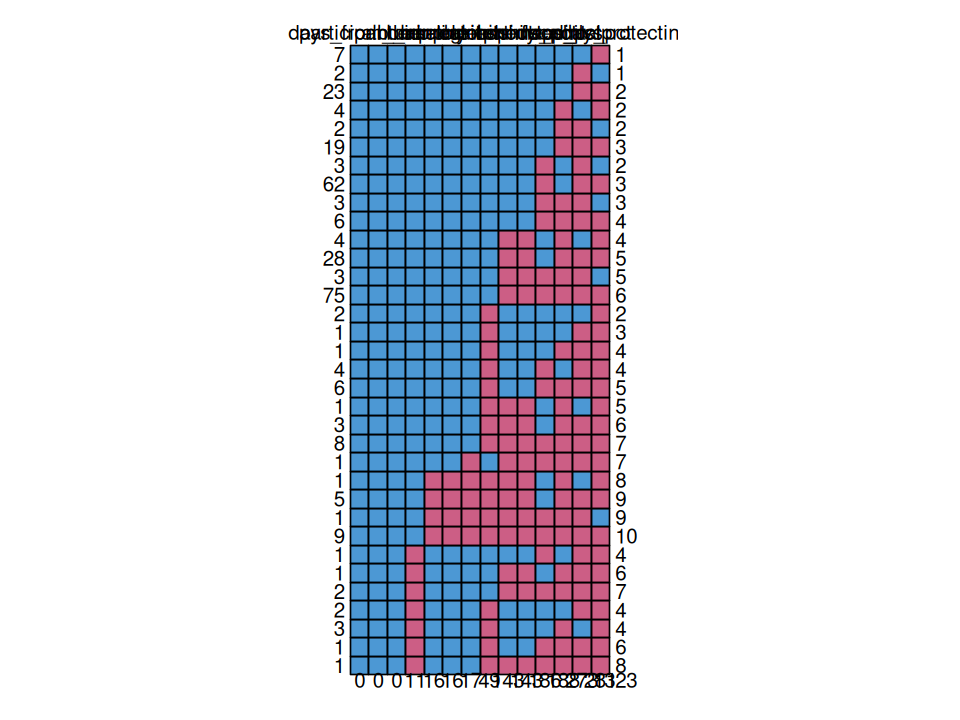

In [449]:
mice::md.pattern(df_labs2_tp)

,participant_id,days_from_baseline,albumin,timepoint,crp,hematocrit,hemoglobin,platelets,esr,eosinophils_pct,lymphocytes_pct,neutrophils_pct,days,fecal_calprotectin,
7,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1
2,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1
23,1,1,1,1,1,1,1,1,1,1,1,1,0,0,2
4,1,1,1,1,1,1,1,1,1,1,1,0,1,0,2
2,1,1,1,1,1,1,1,1,1,1,1,0,0,1,2
19,1,1,1,1,1,1,1,1,1,1,1,0,0,0,3
4,1,1,1,1,1,1,1,1,1,0,0,0,1,0,4
28,1,1,1,1,1,1,1,1,1,0,0,0,0,0,5
2,1,1,1,1,1,1,1,1,0,1,1,1,1,0,2
1,1,1,1,1,1,1,1,1,0,1,1,1,0,0,3


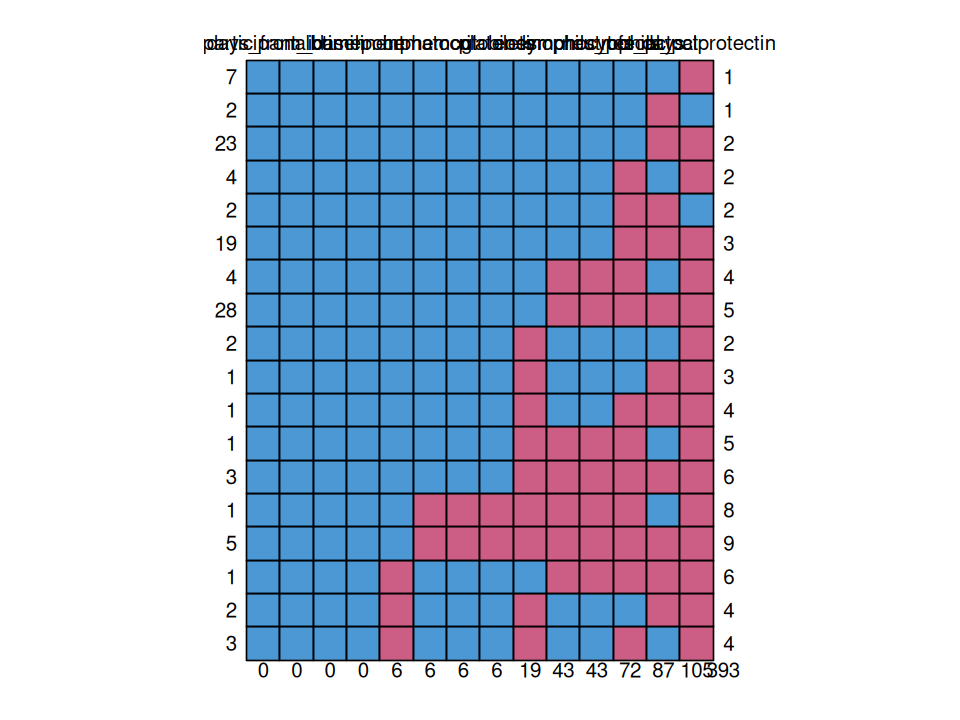

In [450]:
mice::md.pattern(df_labs2_tp  %>% dplyr::filter(!is.na(timepoint)))

In [461]:
df_labs2_tp  %>% dplyr::filter(!is.na(timepoint))  %>% pull(crp)

[1] "0.8"   "0.8"   NA      "<0.8"  "0.8"   NA      "0.8"   "0.8"   "8.0"  
 [10] "0.8"   "2.8"   "1.2"   "<0.8"  "0.8"   "0.8"   "3.4"   "0.8"   NA     
 [19] "2.8"   "0.8"   "2.4"   "0.8"   "0.8"   "2.1"   "2.3"   "0.8"   NA     
 [28] "<0.8"  "<0.8"  "<0.8"  "0.9"   "0.8"   "46.2"  "0.8"   "<0.8"  "<0.8" 
 [37] "0.0"   "0.8"   "<0.8"  "0.8"   "1.7"   "1.7"   "5.4"   "0.8"   "0.8"  
 [46] "1.2"   "0.8"   "0.8"   "4.8"   "0.8"   "4.5"   "1.1"   "16.4"  "6.6"  
 [55] "0.8"   NA      "2.0"   "4.2"   "0.8"   "7.0"   "5.1"   "0.8"   "0.8"  
 [64] "4.9"   "0.8"   "0.8"   "0.8"   NA      "0.8"   "0.6"   "0.8"   "0.8"  
 [73] "16.8"  "0.9"   "0.8"   "0.8"   "0.19"  "<0.03" "6.32"  "<0.03" "1.76" 
 [82] "0.22"  "1.95"  "0.14"  "5.29"  "0.57"  "1.21"  "2.75"  "0.25"  "0.45" 
 [91] "0.16"  "0.04"  "0.83"  "8.17"  "1.81"  "<0.06" "0.06"  "<0.03" "1.88" 
[100] "0.26"  "1.73"  "0.44"  "4.84"  "0.06"  "0.18"  "0.10"  "1.96"  "0.06" 
[109] "2.15"

# Cohort characteristics pre post

In [266]:
md_5p_new  <- read_csv("data/predict_5p_metadata_20260819.csv")

Rows: 1382 Columns: 56
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (50): sample, data_folder, diagnosis, subgroup_primary, subgroup_second...
dbl   (4): days, severity_score, weighted_severity_score, age
date  (2): dob, collection_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [451]:
labs_to_fill <- c(
  "crp",
  "hematocrit",
  "hemoglobin",
  "platelets",
  "esr"
)

In [452]:
model_labs <- df_labs2_tp %>%
  filter(!is.na(timepoint)) %>%
  mutate(.target_row = row_number())

In [462]:
lab_available <- df_labs2_tp %>%
mutate(crp = gsub(crp, pattern = "<", replacement = ""))  %>% 
mutate(crp = as.numeric(crp))  %>% 
mutate(esr = gsub(esr, pattern = "<1", replacement = "1"))  %>% 
mutate(esr = as.numeric(esr))  %>% 
  select(
    participant_id,
    days_from_baseline,
    all_of(labs_to_fill)
  ) %>%
  pivot_longer(
    cols = all_of(labs_to_fill),
    names_to = "lab",
    values_to = "value"
  ) %>%
  filter(!is.na(value))

In [463]:
closest_labs <- model_labs %>%
  select(
    .target_row,
    participant_id,
    timepoint,
    target_day = days_from_baseline
  ) %>%
  tidyr::crossing(lab = labs_to_fill) %>%
  inner_join(
    lab_available,
    by = c("participant_id", "lab"),
    relationship = "many-to-many"
  ) %>%
  mutate(
    distance = abs(days_from_baseline - target_day)
  ) %>%
  group_by(.target_row, lab) %>%
  slice_min(
    distance,
    n = 1,
    with_ties = FALSE
  ) %>%
  ungroup()

In [625]:
closest_labs

.target_row,participant_id,timepoint,target_day,lab,days_from_baseline,value,distance
<int>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
1,001-002,T0,0,crp,0,0.8,0
1,001-002,T0,0,esr,0,6.0,0
1,001-002,T0,0,hematocrit,0,45.6,0
1,001-002,T0,0,hemoglobin,0,15.6,0
1,001-002,T0,0,platelets,0,325.0,0
2,001-009,T0,-39,crp,-39,0.8,0
3,001-010,T0,0,crp,-36,53.5,36
3,001-010,T0,0,esr,-36,93.0,36
3,001-010,T0,0,hematocrit,0,30.1,0


In [626]:
write.csv(closest_labs, "tables/closest_labs.csv")

In [98]:
closest_labs  <- read.csv("tables/closest_labs.csv")
closest_labs$X  <- NULL

### Plotting lab values

In [99]:
closest_labs

.target_row,participant_id,timepoint,target_day,lab,days_from_baseline,value,distance
<int>,<chr>,<chr>,<int>,<chr>,<int>,<dbl>,<int>
1,001-002,T0,0,crp,0,0.8,0
1,001-002,T0,0,esr,0,6.0,0
1,001-002,T0,0,hematocrit,0,45.6,0
1,001-002,T0,0,hemoglobin,0,15.6,0
1,001-002,T0,0,platelets,0,325.0,0
2,001-009,T0,-39,crp,-39,0.8,0
3,001-010,T0,0,crp,-36,53.5,36
3,001-010,T0,0,esr,-36,93.0,36
3,001-010,T0,0,hematocrit,0,30.1,0


In [100]:
md_to_join3  <- md_5p_new  %>% 
                                           dplyr::select(participant_id, timepoint, 
                                                        diagnosis, antitnf_response)   %>% 
 unique

In [101]:
md_to_join4  <- md_to_join3  %>% dplyr::select(1:4)  %>% unique

In [102]:
pt_3p  <- gsub(c('p009',
'p011',
'p014',
'p016',
'p017',
'p018',
'p019',
'p022',
'p023',
'p024',
'p026',
'p027',
'p028',
'p030',
'p031',
'p032',
'p033',
'p034',
'p035',
'p037',
'p041',
'p042',
'p043',
'p044',
'p048',
'p049',
'p050'), pattern = "p", replacement = "001-")

In [103]:
closest_labs  %>% left_join(md_to_join4)  %>% 
mutate(cohort = ifelse(participant_id %in% pt_3p, "3p","5p")) 

Joining with `by = join_by(participant_id, timepoint)`


.target_row,participant_id,timepoint,target_day,lab,days_from_baseline,value,distance,diagnosis,antitnf_response,cohort
<int>,<chr>,<chr>,<int>,<chr>,<int>,<dbl>,<int>,<chr>,<chr>,<chr>
1,001-002,T0,0,crp,0,0.8,0,FGID,NM,5p
1,001-002,T0,0,esr,0,6.0,0,FGID,NM,5p
1,001-002,T0,0,hematocrit,0,45.6,0,FGID,NM,5p
1,001-002,T0,0,hemoglobin,0,15.6,0,FGID,NM,5p
1,001-002,T0,0,platelets,0,325.0,0,FGID,NM,5p
2,001-009,T0,-39,crp,-39,0.8,0,FGID,NM,3p
3,001-010,T0,0,crp,-36,53.5,36,CD,PR,5p
3,001-010,T0,0,esr,-36,93.0,36,CD,PR,5p
3,001-010,T0,0,hematocrit,0,30.1,0,CD,PR,5p


In [104]:
closest_labs2  <- closest_labs  %>% left_join(md_to_join4)  %>% 
mutate(cohort = ifelse(participant_id %in% pt_3p, "3p","5p")) 

Joining with `by = join_by(participant_id, timepoint)`


In [105]:
closest_labs2  %>% group_by(participant_id, cohort, timepoint)  %>% tally()  %>% 
ungroup  %>% 
dplyr::filter(timepoint == "T0")  %>% 
group_by(cohort)  %>% 
tally()

cohort,n
<chr>,<int>
3p,22
5p,65


In [106]:
closest_labs2  %>% group_by(participant_id, cohort, timepoint)  %>% tally()  %>% 
ungroup  %>% 
dplyr::filter(timepoint == "R")  %>% 
group_by(cohort)  %>% 
tally()

cohort,n
<chr>,<int>
3p,8
5p,13


### By diagnosis

In [699]:
col_pal  <- scales::hue_pal()(4)
names(col_pal)  <- c("CD","FGID","HEA","UC")

In [713]:
col_pal[["OTH"]]  <- "grey70"

Warning message in wilcox.test.default(c(0.8, 0, 4.2, 0.8, 0.8, 0.6, 0.8, 0.19, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(6, 55, 11, 1, 12, 5, 9, 1, 1, 9), c(93, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(45.6, 37.8, 43.8, 32.4, 42.4, 36.5, 37.4, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(15.6, 12.9, 14.3, 10.9, 14.3, 12.8, 12.7, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(325, 307, 336, 235, 421, 248, 337, 343, :
“cannot compute exact p-value with ties”


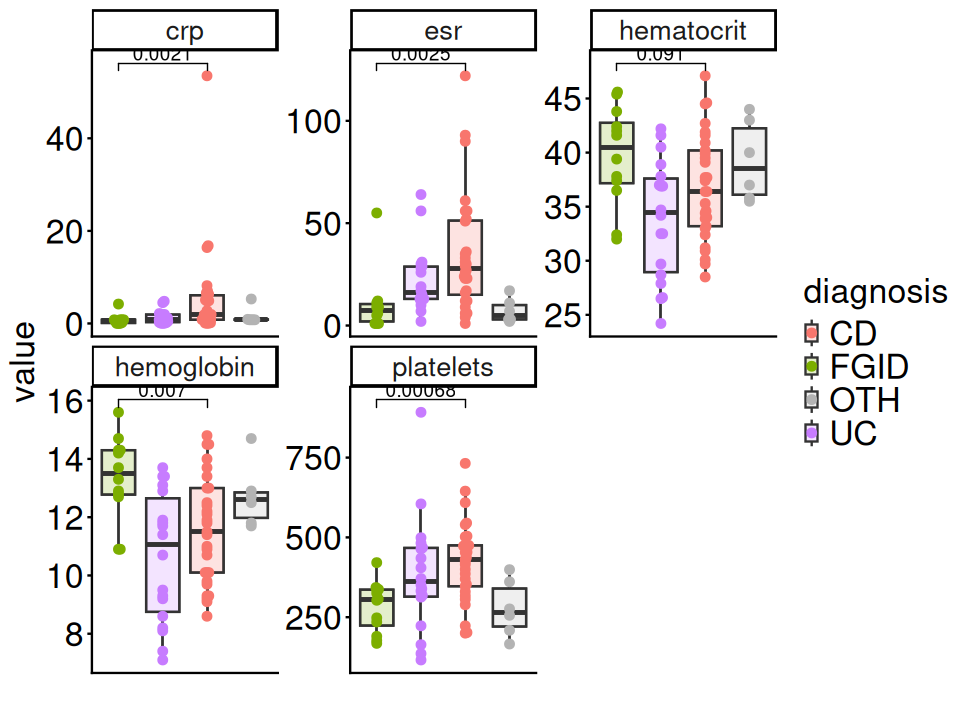

In [714]:
closest_labs2  %>% 
dplyr::filter(timepoint == "T0" & cohort == "5p" )  %>% 
ggplot(aes(x = factor(diagnosis, levels = c("HEA","FGID","UC","CD","OTH")), y = value))  +
geom_boxplot(outlier.shape = NA) +
facet_wrap(~lab, scales = "free") +
geom_boxplot(outlier.shape = NA, aes(fill = diagnosis), alpha = 0.2) +
ggbeeswarm::geom_beeswarm(size = 2, aes(color = diagnosis)) +
scale_color_manual(values = col_pal) +
scale_fill_manual(values = col_pal) +
theme_classic() +
ggtheme() +
xlab("") +
theme(axis.text.x = element_blank(), axis.ticks.x = element_blank()) + 
ggpubr::stat_compare_means(label = "p.format", comparisons = list(c(1,3)))
     

#ggsave("figures/cohort_characterization_gut/age_validation.svg", width = 16, height = 10, units = "cm")

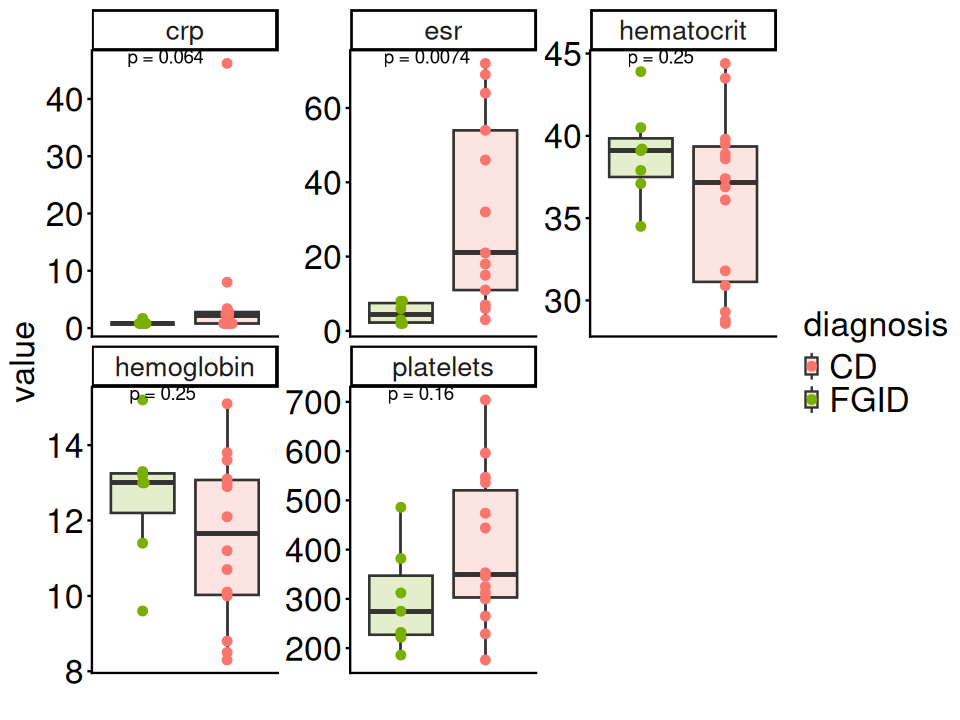

In [703]:
closest_labs2  %>% 
dplyr::filter(timepoint == "T0" & cohort == "3p")  %>% 
ggplot(aes(x = factor(diagnosis, levels = c("HEA","FGID","UC","CD","OTH")), y = value))  +
geom_boxplot(outlier.shape = NA) +
facet_wrap(~lab, scales = "free") +
geom_boxplot(outlier.shape = NA, aes(fill = diagnosis), alpha = 0.2) +
ggbeeswarm::geom_beeswarm(size = 2, aes(color = diagnosis)) +
scale_color_manual(values = col_pal) +
scale_fill_manual(values = col_pal) +
theme_classic() +
ggtheme() +
xlab("") +
theme(axis.text.x = element_blank(), axis.ticks.x = element_blank()) + 
ggpubr::stat_compare_means(label = "p.format")
     
     

#ggsave("figures/cohort_characterization_gut/age_validation.svg", width = 16, height = 10, units = "cm")

Warning message in wilcox.test.default(c(0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0, 1.7, 4.2, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(6, 3, 2, 8, 8, 2, 6, 55, 11, 1, 12, 5, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(45.6, 34.5, 40.5, 37.9, 37.1, 39.1, 43.9, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(15.6, 9.6, 13.2, 13, 11.4, 13, 15.2, 12.9, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(325, 312, 232, 275, 382, 222, 186, 307, :
“cannot compute exact p-value with ties”


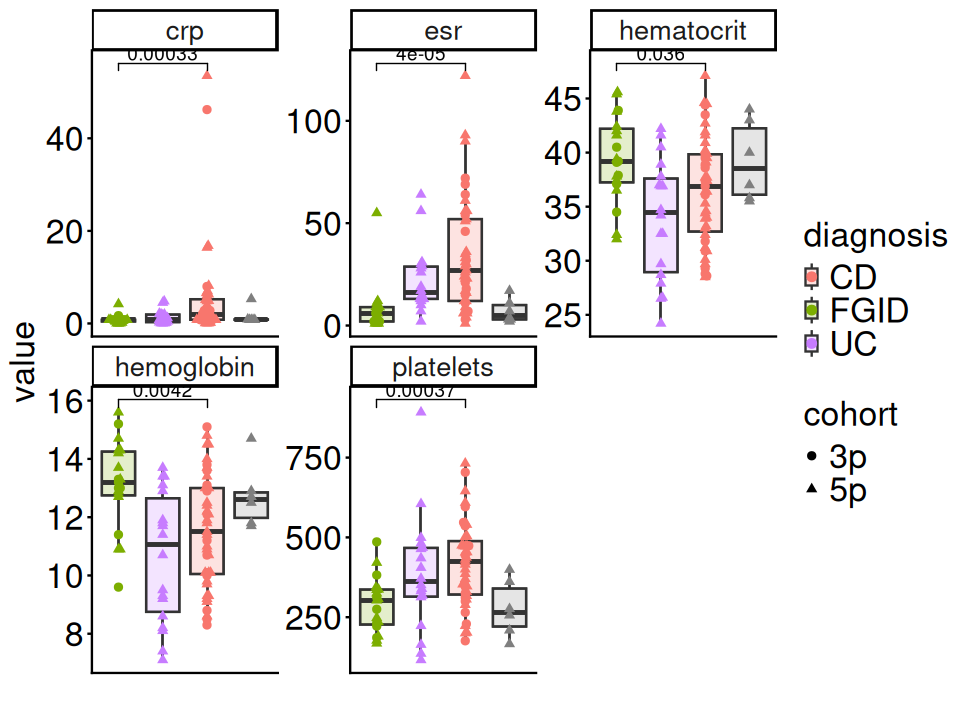

In [712]:
closest_labs2  %>% 
dplyr::filter(timepoint == "T0")  %>% 
ggplot(aes(x = factor(diagnosis, levels = c("HEA","FGID","UC","CD","OTH")), y = value))  +
geom_boxplot(outlier.shape = NA) +
facet_wrap(~lab, scales = "free") +
geom_boxplot(outlier.shape = NA, aes(fill = diagnosis), alpha = 0.2) +
ggbeeswarm::geom_beeswarm(size = 2, aes(color = diagnosis, shape = cohort)) +
scale_color_manual(values = col_pal) +
scale_fill_manual(values = col_pal) +
theme_classic() +
ggtheme() +
xlab("") +
theme(axis.text.x = element_blank(), axis.ticks.x = element_blank()) + 
ggpubr::stat_compare_means(label = "p.format", comparisons = list(c(1,3)))
     

#ggsave("figures/cohort_characterization_gut/age_validation.svg", width = 16, height = 10, units = "cm")

In [ ]:
labs2  <- levels(factor(closest_lab2$lab))

Warning message in wilcox.test.default(c(0.8, 0.8, 0.8, 0.8, 0.8, 1.7), c(0.8, 0.8, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.8, 0, 4.2, 0.8, 0.8, 0.6, 0.8, 0.19, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.8, 0.8, 0.8, 0.8, 0.8, 1.7), c(0.8, 0.8, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.8, 0, 4.2, 0.8, 0.8, 0.6, 0.8, 0.19, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(3, 2, 8, 8, 2, 6), c(18, 46, 7, 11, 64, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(6, 55, 11, 1, 12, 5, 9, 1, 1, 9), c(93, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(3, 2, 8, 8, 2, 6), c(18, 46, 7, 11, 64, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(6, 55, 11, 1, 12, 5, 9, 1, 1, 9), c(93, :
“cannot compute exact p-value with ties”


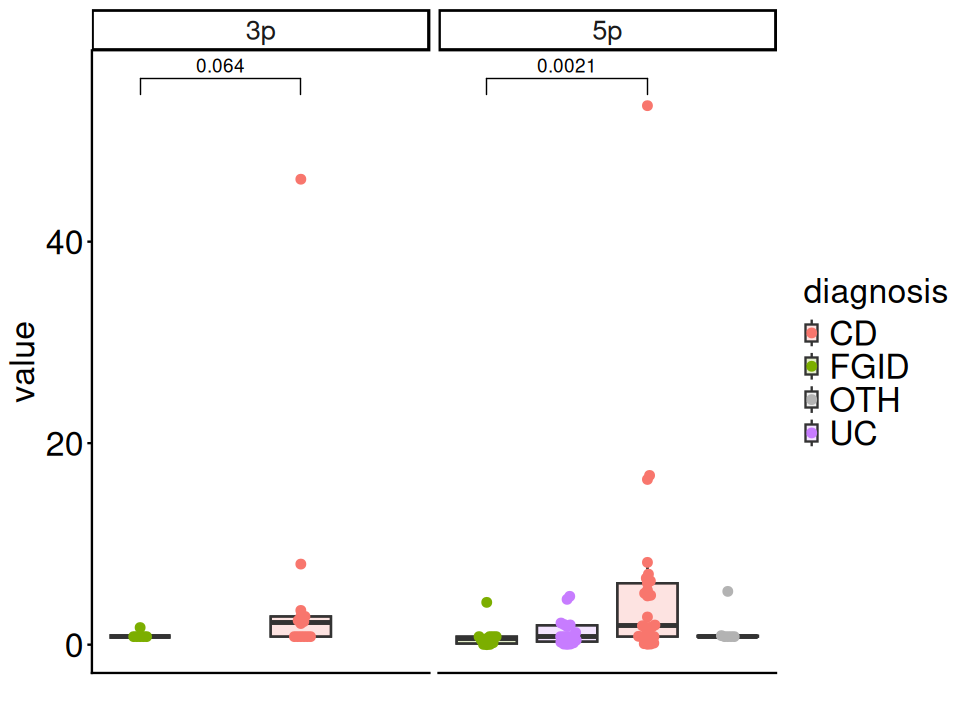

Warning message in wilcox.test.default(c(45.6, 37.8, 43.8, 32.4, 42.4, 36.5, 37.4, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(45.6, 37.8, 43.8, 32.4, 42.4, 36.5, 37.4, :
“cannot compute exact p-value with ties”


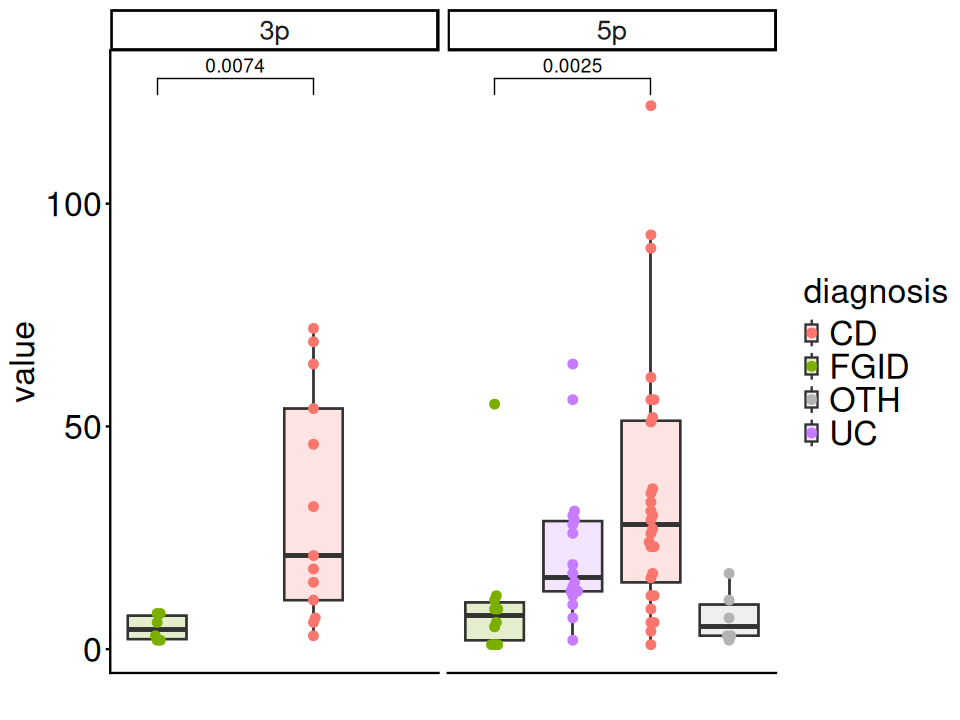

Warning message in wilcox.test.default(c(9.6, 13.2, 13, 11.4, 13, 15.2, 13.3), c(10, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(15.6, 12.9, 14.3, 10.9, 14.3, 12.8, 12.7, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(9.6, 13.2, 13, 11.4, 13, 15.2, 13.3), c(10, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(15.6, 12.9, 14.3, 10.9, 14.3, 12.8, 12.7, :
“cannot compute exact p-value with ties”


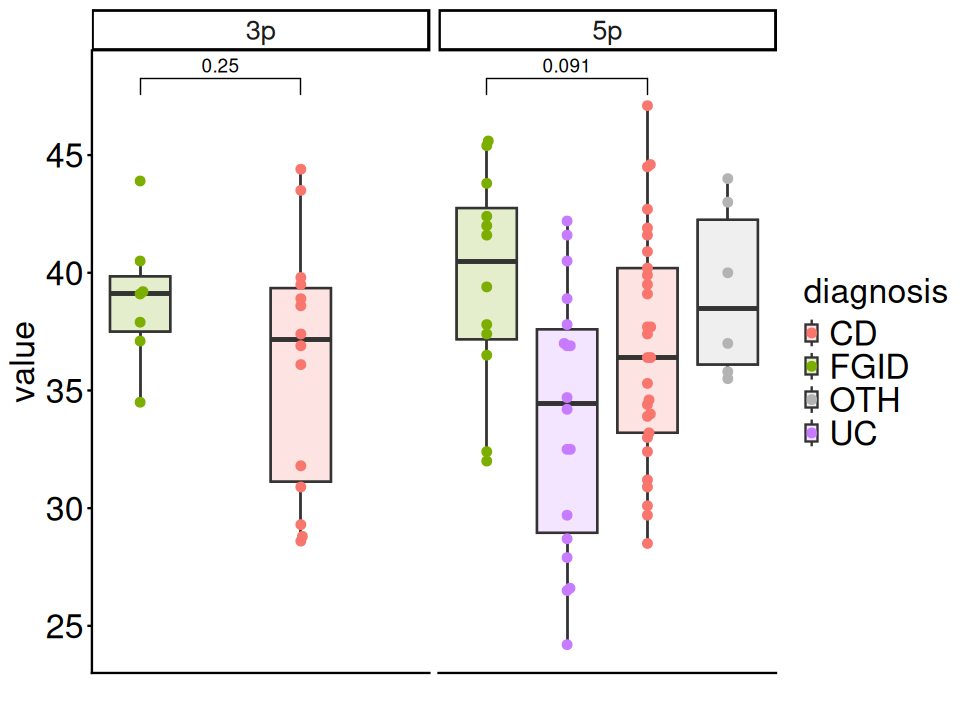

Warning message in wilcox.test.default(c(312, 232, 275, 382, 222, 186, 486), c(596, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(325, 307, 336, 235, 421, 248, 337, 343, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(312, 232, 275, 382, 222, 186, 486), c(596, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(325, 307, 336, 235, 421, 248, 337, 343, :
“cannot compute exact p-value with ties”


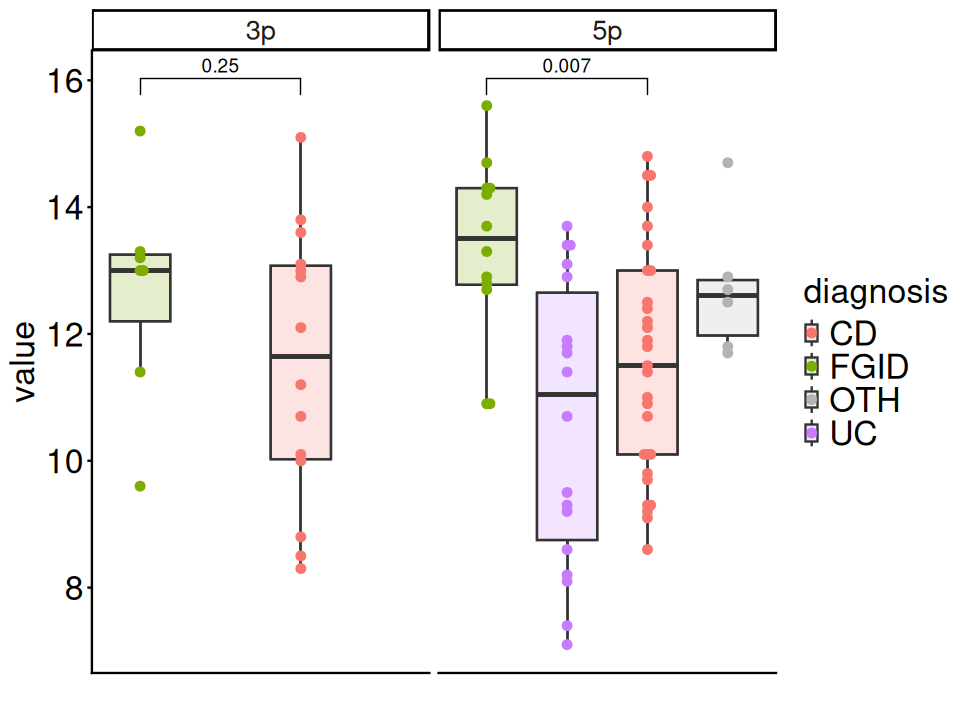

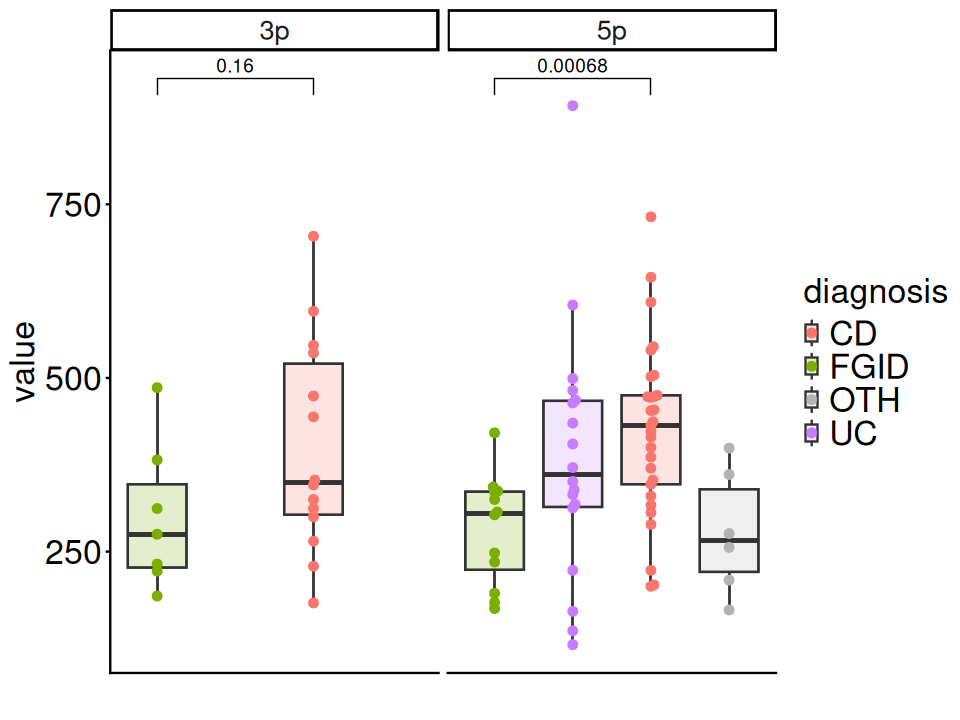

In [720]:
for(i in labs2){
    
p  <- closest_labs2  %>% 
dplyr::filter(timepoint == "T0" & lab == i)  %>% 
ggplot(aes(x = factor(diagnosis, levels = c("HEA","FGID","UC","CD","OTH")), y = value))  +
geom_boxplot(outlier.shape = NA) +
geom_boxplot(outlier.shape = NA, aes(fill = diagnosis), alpha = 0.2) +
ggbeeswarm::geom_beeswarm(size = 2, aes(color = diagnosis)) +
scale_color_manual(values = col_pal) +
scale_fill_manual(values = col_pal) +
    facet_wrap(~cohort) +
theme_classic() +
ggtheme() +
xlab("") +
theme(axis.text.x = element_blank(), axis.ticks.x = element_blank()) + 
ggpubr::stat_compare_means(label = "p.format", comparisons = list(c(1,3)))
print(p)
    
ggsave(p, filename = paste0("figures/clinical_labs/",i,".svg"),
       width = 18, height = 9, 
       units = "cm", create.dir = TRUE)    
}

#ggsave("figures/cohort_characterization_gut/age_validation.svg", width = 16, height = 10, units = "cm")

Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_boxplot()`).”
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_boxplot()`).”
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_signif()`).”
Warning message in wilcox.test.default(c(0.8, 0.8, 0.8, 0.8, 0.8, 1.7), c(0.8, 0.8, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(0.8, 0, 4.2, 0.8, 0.8, 0.6, 0.8, 0.19, :
“cannot compute exact p-value with ties”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 6 rows containing missing values or values outside the scale range
(`geom_signif()`).”
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_boxplot()`).”
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_boxplot()`).”
Warning message:
“Removed 1 row 

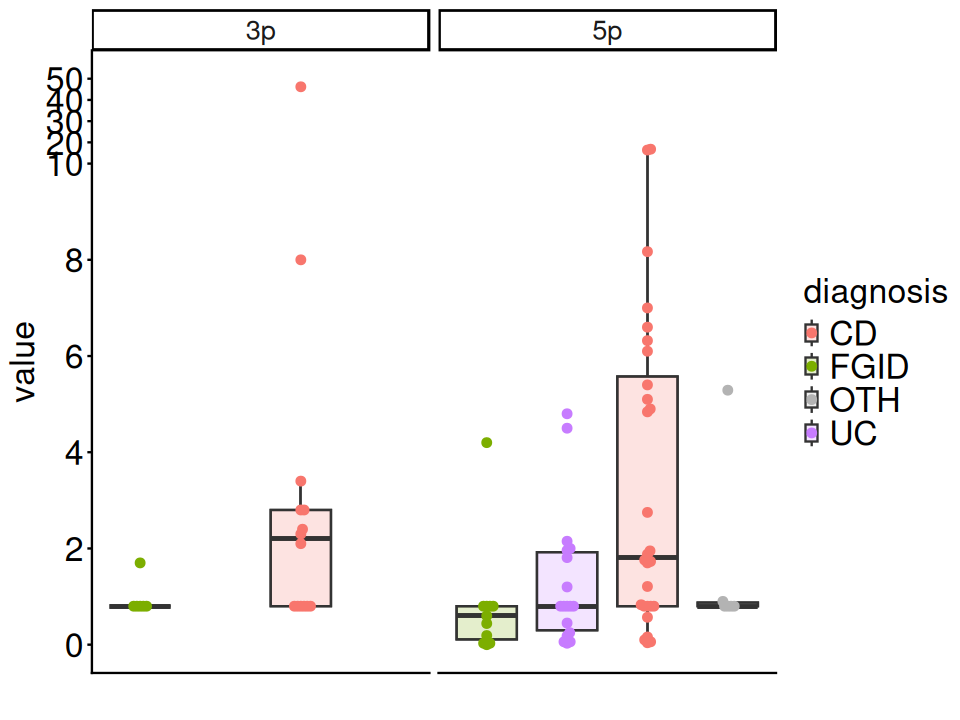

In [724]:
for(i in "crp"){
    
p  <- closest_labs2  %>% 
  dplyr::filter(timepoint == "T0" & lab == i)  %>% 
  ggplot(aes(
    x = factor(diagnosis, levels = c("HEA","FGID","UC","CD","OTH")),
    y = value
  ))  +
  geom_boxplot(outlier.shape = NA) +
  geom_boxplot(outlier.shape = NA, aes(fill = diagnosis), alpha = 0.2) +
  ggbeeswarm::geom_beeswarm(size = 2, aes(color = diagnosis)) +
  scale_color_manual(values = col_pal) +
  scale_fill_manual(values = col_pal) +
  scale_y_continuous(
    trans = split_trans,
    breaks = c(0, 2, 4, 6, 8, 10, 20, 30, 40, 50),
    limits = c(0, 50)
  ) +
  facet_wrap(~cohort) +
  theme_classic() +
  ggtheme() +
  xlab("") +
  theme(
    axis.text.x = element_blank(),
    axis.ticks.x = element_blank()
  ) + 
  ggpubr::stat_compare_means(
    label = "p.format",
    comparisons = list(c(1,3))
  )

print(p)
    
ggsave(p, filename = paste0("figures/clinical_labs/",i,".svg"),
       width = 18, height = 9, 
       units = "cm", create.dir = TRUE)    
}



### By timepoint

In [668]:
sample_has_r  <- closest_labs2  %>% 
group_by(participant_id, cohort, timepoint)  %>% tally()  %>% 
ungroup  %>% 
dplyr::filter(timepoint == "R")  %>% 
group_by(participant_id)  %>% 
tally()  %>% pull(participant_id)

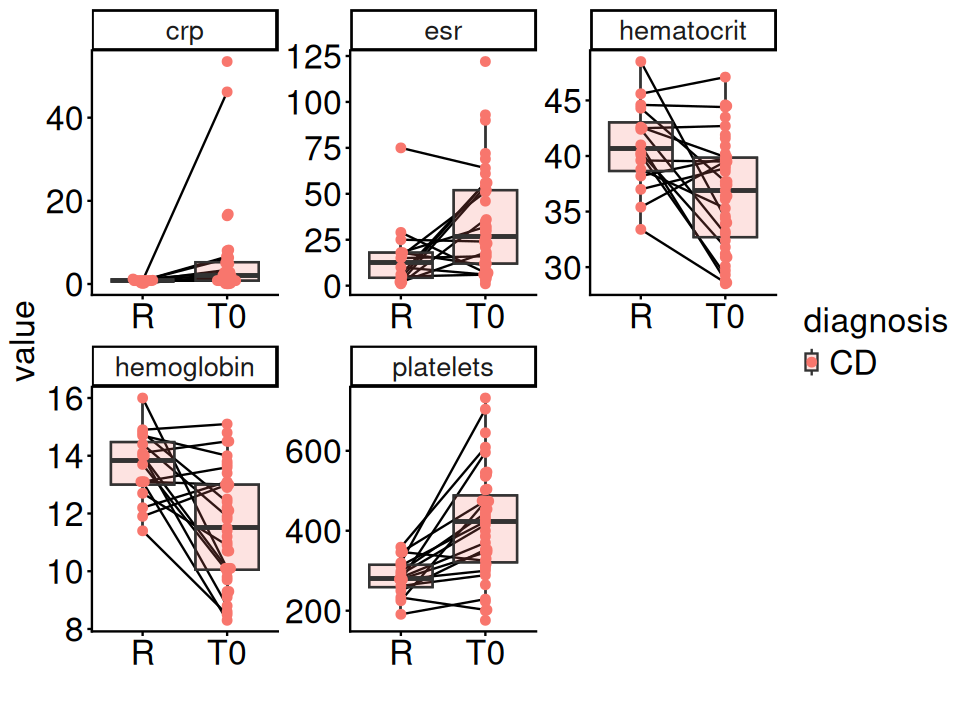

In [659]:
closest_labs2  %>% dplyr::filter(diagnosis == "CD" & timepoint != "R2")  %>% 
ggplot(aes(x = timepoint, y = value))  +
geom_boxplot(outlier.shape = NA) +
geom_line(aes(group = participant_id)) +
facet_wrap(~lab, scales = "free") +
geom_boxplot(outlier.shape = NA, aes(fill = diagnosis), alpha = 0.2) +
ggbeeswarm::geom_beeswarm(size = 2, aes(color = diagnosis)) +
theme_classic() +
ggtheme() +
xlab("") 


#ggsave("figures/cohort_characterization_gut/age_validation.svg", width = 16, height = 10, units = "cm")

In [669]:
sample_has_r

[1] "001-011" "001-014" "001-018" "001-019" "001-022" "001-032" "001-040"
 [8] "001-041" "001-048" "001-055" "001-058" "001-059" "001-062" "001-064"
[15] "001-086" "001-089" "001-101" "003-006" "003-007" "003-034" "003-039"

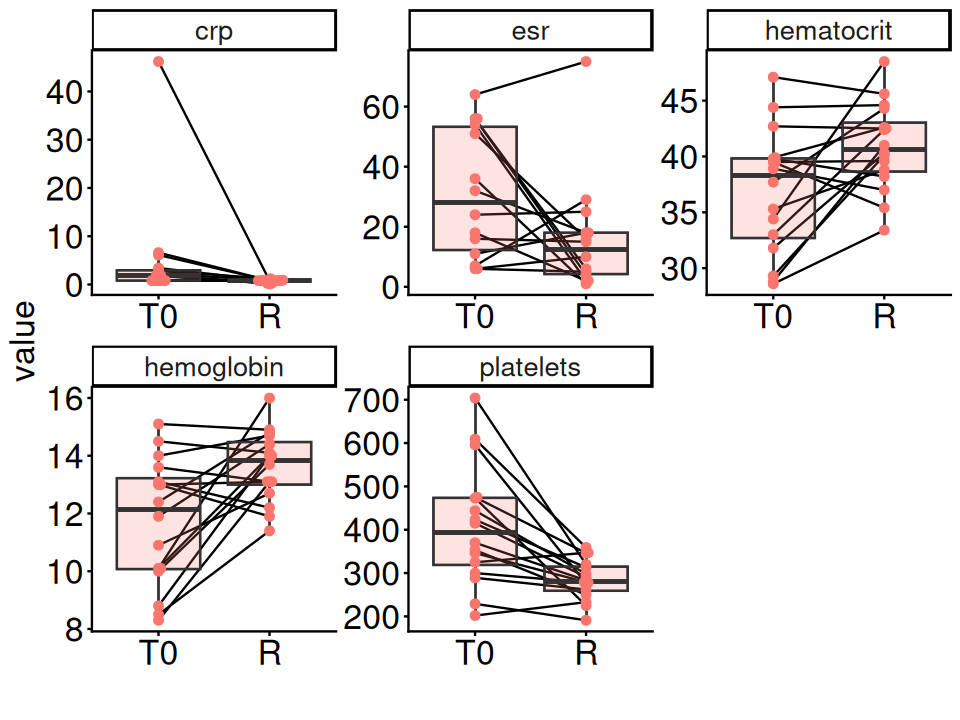

In [721]:
closest_labs2  %>% dplyr::filter(diagnosis == "CD" & timepoint != "R2" & participant_id %in% sample_has_r)  %>% 
ggplot(aes(x = factor(timepoint, levels = c("T0","R")), y = value))  +
geom_boxplot(outlier.shape = NA) +
geom_line(aes(group = participant_id)) +
facet_wrap(~lab, scales = "free") +
geom_boxplot(outlier.shape = NA, aes(fill = diagnosis), alpha = 0.2) +
ggbeeswarm::geom_beeswarm(size = 2, aes(color = diagnosis)) +
theme_classic() +
ggtheme() +
xlab("") + NoLegend()


ggsave("figures/clinical_labs/t0_vs_R.svg", width = 15, height = 15, units = "cm", create.dir = TRUE)

In [722]:
compress <- 0.04411765

split_trans <- scales::trans_new(
  "split",
  transform = function(y) {
    ifelse(y <= 10,
           y,
           10 + (y - 10) * compress)
  },
  inverse = function(y) {
    ifelse(y <= 10,
           y,
           10 + (y - 10) / compress)
  }
)

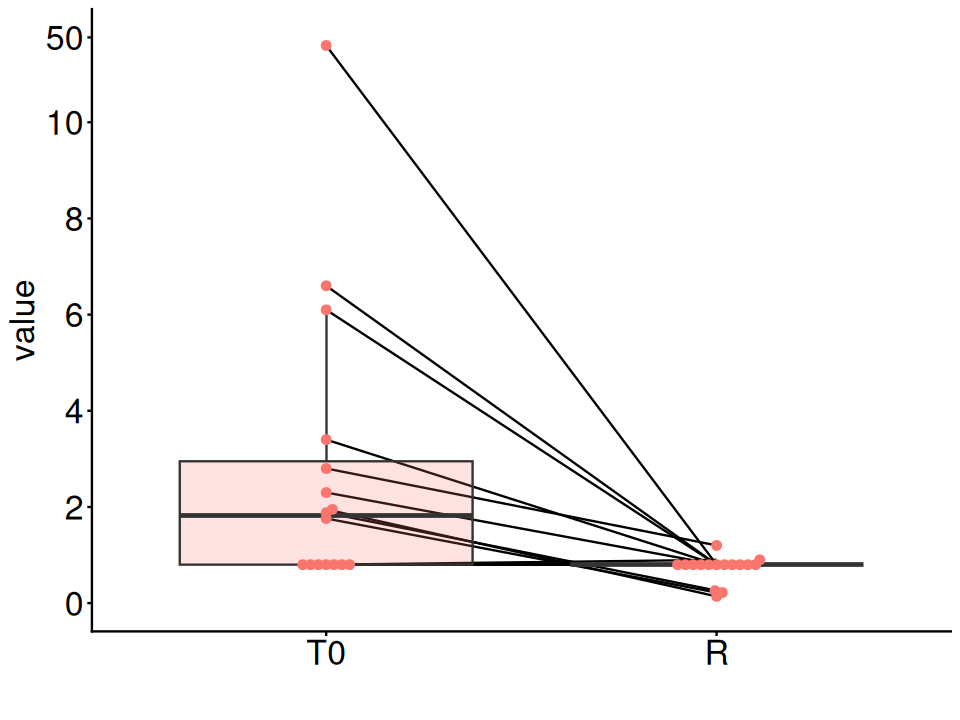

In [727]:
closest_labs2 %>%
  dplyr::filter(
    diagnosis == "CD" &
    timepoint != "R2" &
    participant_id %in% sample_has_r &
    lab == "crp"
  ) %>%
  ggplot(aes(
    x = factor(timepoint, levels = c("T0", "R")),
    y = value
  )) +
  geom_line(aes(group = participant_id)) +
  geom_boxplot(
    outlier.shape = NA,
    aes(fill = diagnosis),
    alpha = 0.2
  ) +
  ggbeeswarm::geom_beeswarm(
    size = 2,
    aes(color = diagnosis)
  ) +
  scale_y_continuous(
    trans = split_trans,
    breaks = c(0, 2, 4, 6, 8, 10, 50),
    limits = c(0, 50)
  ) +
  theme_classic() +
  ggtheme() +
  xlab("") +
  NoLegend()

In [729]:
ggsave("figures/clinical_labs/crp_t0_R.svg", width = 5.5, height = 7, units = "cm")

In [684]:
closest_labs2  %>% 
dplyr::filter(diagnosis == "CD" & timepoint != "R2" & participant_id %in% sample_has_r)  %>% 
group_by(lab)  %>% 
arrange(participant_id)  %>% 
rstatix::wilcox_test(value~timepoint, paired = T, )

,lab,.y.,group1,group2,n1,n2,statistic,p
,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>
1,crp,value,R,T0,16,16,1.0,0.00805
2,esr,value,R,T0,14,14,26.0,0.10200
3,hematocrit,value,R,T0,16,16,109.5,0.03400
4,hemoglobin,value,R,T0,16,16,114.0,0.01550
5,platelets,value,R,T0,16,16,5.5,0.00134
